# AI651 PA2 · Question 2 · Notebook 4 — What can data fix?

Chooses model D on the **validation** split, trains B, C and D (seeds 0 and 1) and builds
**Table 5**. This is the longest notebook; on a T4 expect roughly 1–2 hours for the six runs
plus the optional design comparison.

**If the session disconnects:** reconnect (GPU runtime), then run the notebook again from the
top. Finished runs are loaded from Drive, an interrupted run continues from its last checkpoint
(end of every epoch and every 5 minutes inside an epoch), and cached metrics are not recomputed.

In [1]:
# 0) Drive, code and GPU -- run this first in every session
PROJECT = "/content/drive/MyDrive/AI651_PA2"   # data, checkpoints, results, figures live here
UPDATE_CODE = False   # True -> upload pa2_code.zip again (e.g. after you edit a script)

from google.colab import drive
drive.mount("/content/drive")

import os, sys, io, zipfile
CODE_DIR = os.path.join(PROJECT, "code")
os.makedirs(CODE_DIR, exist_ok=True)
if UPDATE_CODE or not os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")):
    from google.colab import files
    print("Upload pa2_code.zip (or the individual pa2/*.py files). "
          "It is stored on Drive, so this is only needed once.")
    for name, blob in files.upload().items():
        if name.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(blob)).extractall(CODE_DIR)
        elif name.endswith(".py"):
            os.makedirs(os.path.join(CODE_DIR, "pa2"), exist_ok=True)
            clean = name.split(" (")[0].removesuffix(".py") + ".py"   # Colab renames "x (1).py"
            with open(os.path.join(CODE_DIR, "pa2", clean), "wb") as f:
                f.write(blob)
assert os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")), "pa2 package not found on Drive"
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
for m in [m for m in list(sys.modules) if m == "pa2" or m.startswith("pa2.")]:
    del sys.modules[m]                         # always import the version on Drive

import numpy as np
import matplotlib.pyplot as plt
import pa2
from pa2 import config, data, models, train, evaluation, visuals, checks, tables, utils
from pa2.pipeline import Context
from pa2.utils import show_table
%matplotlib inline
print("pa2 version", pa2.__version__)

Mounted at /content/drive
pa2 version 1.0


In [2]:
Q2_11_COMMITTED = True
assert Q2_11_COMMITTED, "Commit your Q2.11 predictions before training models B-D."

In [3]:
ctx = Context(PROJECT)
ctx.load_data();   # first run: downloads Moving MNIST (~800 MB) to Drive; later runs load it from there

Device: Tesla T4 (15 GB), torch 2.11.0+cu130
Loading Moving MNIST (downloaded to Drive the first time) ...
{'train': (8000, 20, 1, 64, 64), 'val': (1000, 20, 1, 64, 64), 'test': (1000, 20, 1, 64, 64)}


## Model D candidates
All candidates stay within 721,176 parameters and keep model A's input/output shapes, the
9-step rollout and the training protocol. You still need to show in **Q2.12**, with the same
calculation as Q2.3, that your chosen design has a strictly larger one-step reach than model A.

To try your own design, add it in the next cell, e.g.
`config.ARCHS["D_mine"] = dict(patch=4, hidden=(48, 48), kernels=(5, 3), dilations=(1, 1))`
(odd kernels only), and list it in `CANDIDATES`.

In [4]:
# config.ARCHS["D_mine"] = dict(patch=4, hidden=(48, 48), kernels=(5, 3), dilations=(1, 1))
CANDIDATES = ["D_k5", "D_dil", "D_p8"]
for a in CANDIDATES:
    print(f"{a:8s} {models.check_arch_budget(a, is_model_d=True):>9,} params   {config.ARCHS[a]}")

D_k5       709,520 params   {'patch': 4, 'hidden': (46, 46), 'kernels': (5, 5), 'dilations': (1, 1)}
D_dil      480,784 params   {'patch': 4, 'hidden': (64, 64), 'kernels': (3, 3), 'dilations': (1, 2)}
D_p8       594,496 params   {'patch': 8, 'hidden': (64, 64), 'kernels': (3, 3), 'dilations': (1, 1)}


### Optional: compare candidates on the validation split
Each candidate is trained once (seed 0, speed augmentation as for model D) for `PILOT_EPOCHS`
epochs and scored on the 1,000 validation videos only — the test split is never used to choose.
Results are cached, so re-running is free.

In [5]:
RUN_PILOTS = True
PILOT_EPOCHS = 10
pilots = [ctx.pilot(a, epochs=PILOT_EPOCHS) for a in CANDIDATES] if RUN_PILOTS else []
if pilots:
    hdr = ["Candidate", "Params", "val E(5) 1×", "val E(2) 1×", "val E(2) 2×", "val E(2) 3×", "s/epoch"]
    rows = [[p["arch"], f"{p['params']:,}", utils.fmt(p["val_E5_1x"]), utils.fmt(p["val_E2_1x"]),
             utils.fmt(p["val_E2_2x"]), utils.fmt(p["val_E2_3x"]), utils.fmt(p["mean_epoch_time_s"])]
            for p in pilots]
    show_table(utils.save_table(ctx.paths, "pilot_D_validation", hdr, rows,
                                note=f"Validation split, seed 0, {PILOT_EPOCHS} epochs each."))

[D_k5_e10/seed0] resuming at epoch 6, batch 146
[D_k5_e10/seed0] epoch  6/10  loss 0.04021  618.3 s
[D_k5_e10/seed0] epoch  7/10  loss 0.04020  22.6 s
[D_k5_e10/seed0] epoch  8/10  loss 0.04019  23.2 s
[D_k5_e10/seed0] epoch  9/10  loss 0.04021  24.0 s
[D_k5_e10/seed0] epoch 10/10  loss 0.04020  25.5 s  val E5 0.03947
[D_k5_e10/seed0] done: 593.7 s/epoch
[D_dil_e10/seed0] epoch  1/10  loss 0.04645  17.2 s
[D_dil_e10/seed0] epoch  2/10  loss 0.03959  16.3 s
[D_dil_e10/seed0] epoch  3/10  loss 0.03890  16.0 s
[D_dil_e10/seed0] epoch  4/10  loss 0.03794  16.1 s
[D_dil_e10/seed0] epoch  5/10  loss 0.03712  16.4 s  val E5 0.03547
[D_dil_e10/seed0] epoch  6/10  loss 0.03637  16.6 s
[D_dil_e10/seed0] epoch  7/10  loss 0.03562  16.4 s
[D_dil_e10/seed0] epoch  8/10  loss 0.03504  16.3 s
[D_dil_e10/seed0] epoch  9/10  loss 0.03465  16.2 s
[D_dil_e10/seed0] epoch 10/10  loss 0.03420  16.3 s  val E5 0.03234
[D_dil_e10/seed0] done: 16.4 s/epoch
[D_p8_e10/seed0] epoch  1/10  loss 0.04933  4.2 s
[D_p

| Candidate | Params | val E(5) 1× | val E(2) 1× | val E(2) 2× | val E(2) 3× | s/epoch |
|---|---|---|---|---|---|---|
| D_k5 | 709,520 | 0.0395 | 0.0395 | 0.0395 | 0.0395 | 594 |
| D_dil | 480,784 | 0.0323 | 0.0300 | 0.0320 | 0.0344 | 16.4 |
| D_p8 | 594,496 | 0.0392 | 0.0393 | 0.0392 | 0.0392 | 4.22 |

Validation split, seed 0, 10 epochs each.

### Choose model D
Set `D_ARCH` to your choice. If left as `None`, an earlier choice is kept; otherwise the
candidate with the lowest validation E(2) averaged over 1×, 2× and 3× is used. State your
selection criterion in Q2.12.

In [6]:
D_ARCH = None
prev = utils.load_json(os.path.join(ctx.paths["results"], "d_choice.json"))
if D_ARCH is None:
    if prev:
        D_ARCH = prev["d_arch"]
    elif pilots:
        D_ARCH = min(pilots, key=lambda p: np.mean([p["val_E2_1x"], p["val_E2_2x"], p["val_E2_3x"]]))["arch"]
    else:
        D_ARCH = "D_k5"
if prev and prev["d_arch"] != D_ARCH:
    print(f"NOTE: model D changes from {prev['d_arch']} to {D_ARCH}; runs of the old design stay on Drive.")
ctx.set_d_arch(D_ARCH)

Model D architecture: D_dil {'patch': 4, 'hidden': (64, 64), 'kernels': (3, 3), 'dilations': (1, 2)} (480,784 params)


## Train B, C and D (seeds 0 and 1)
Ordered by seed, so all seed-0 models finish first.

In [7]:
for seed in config.SEEDS:
    for key in ("B", "C", "D"):
        ctx.train(key, seed)

[B/seed0] epoch  1/30  loss 0.04611  11.3 s
[B/seed0] epoch  2/30  loss 0.03990  11.3 s
[B/seed0] epoch  3/30  loss 0.03885  11.3 s
[B/seed0] epoch  4/30  loss 0.03716  11.3 s
[B/seed0] epoch  5/30  loss 0.03524  11.4 s  val E5 0.03401
[B/seed0] epoch  6/30  loss 0.03349  11.4 s
[B/seed0] epoch  7/30  loss 0.03197  11.4 s
[B/seed0] epoch  8/30  loss 0.03091  11.4 s
[B/seed0] epoch  9/30  loss 0.03019  11.4 s
[B/seed0] epoch 10/30  loss 0.02972  11.4 s  val E5 0.02917
[B/seed0] epoch 11/30  loss 0.02930  11.4 s
[B/seed0] epoch 12/30  loss 0.02905  11.5 s
[B/seed0] epoch 13/30  loss 0.02859  11.4 s
[B/seed0] epoch 14/30  loss 0.02812  11.5 s
[B/seed0] epoch 15/30  loss 0.02777  11.5 s  val E5 0.02755
[B/seed0] epoch 16/30  loss 0.02729  11.5 s
[B/seed0] epoch 17/30  loss 0.02696  11.5 s
[B/seed0] epoch 18/30  loss 0.02643  11.5 s
[B/seed0] epoch 19/30  loss 0.02599  11.5 s
[B/seed0] epoch 20/30  loss 0.02566  11.5 s  val E5 0.02538
[B/seed0] epoch 21/30  loss 0.02518  11.5 s
[B/seed0] ep

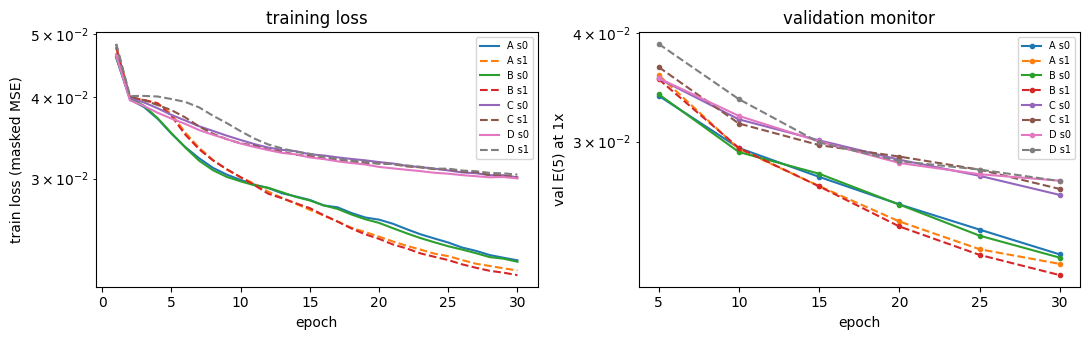

In [8]:
ctx.plot_curves(["A", "B", "C", "D"], os.path.join(ctx.paths["figures"], "training_curves_ABCD.png"))
plt.show()

## Table 5

In [9]:
train_hw = sorted({h for k in ("A", "B", "C", "D") for s in config.SEEDS
                   for h in ctx.train_log(k, s)["hardware"]})
if len(train_hw) > 1:
    print("WARNING: training ran on different hardware -> per-epoch times are not comparable:", train_hw)
hw = f"training: {'; '.join(train_hw)} | inference: {utils.hardware_string(ctx.device)}"
show_table(tables.table5(ctx, hw))

| Model | E(5) 1× | C_M | E_M | C_R | E_R | E(2) 1× | E(2) 2× | E(2) 3× | Params | Train s/epoch | Inference s |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 0.0222 (0.0225, 0.0219) | 0.00199 (0.00176, 0.00222) | 0.0228 (0.0231, 0.0226) | 0.00322 (0.00280, 0.00364) | 0.0239 (0.0240, 0.0238) | 0.0188 (0.0190, 0.0185) | 0.0453 (0.0443, 0.0463) | 0.0530 (0.0524, 0.0536) | 480,784 | 10.7 (10.4, 10.9) | 0.465 (0.460, 0.471) |
| B | 0.0217 (0.0223, 0.0211) | 0.00131 (0.00123, 0.00138) | 0.0217 (0.0223, 0.0211) | 0.00158 (0.00153, 0.00164) | 0.0218 (0.0223, 0.0213) | 0.0182 (0.0188, 0.0177) | 0.0435 (0.0429, 0.0442) | 0.0473 (0.0461, 0.0484) | 480,784 | 11.5 (11.5, 11.5) | 0.433 (0.431, 0.435) |
| C | 0.0265 (0.0262, 0.0267) | 0.00144 (0.00147, 0.00142) | 0.0267 (0.0265, 0.0270) | 0.00277 (0.00250, 0.00304) | 0.0277 (0.0274, 0.0280) | 0.0232 (0.0231, 0.0232) | 0.0286 (0.0287, 0.0285) | 0.0333 (0.0335, 0.0331) | 480,784 | 10.9 (10.9, 10.9) | 0.440 (0.438, 0.442) |
| D | 0.0273 (0.0273, 0.0273) | 7.71e-04 (8.72e-04, 6.69e-04) | 0.0275 (0.0275, 0.0275) | 0.00184 (0.00175, 0.00193) | 0.0284 (0.0283, 0.0284) | 0.0245 (0.0245, 0.0246) | 0.0290 (0.0287, 0.0293) | 0.0327 (0.0325, 0.0330) | 480,784 | 16.3 (16.3, 16.3) | 0.708 (0.706, 0.709) |

Test split. Model D = D_dil. Timings on training: Tesla T4 (15 GB), torch 2.11.0+cu130 | inference: Tesla T4 (15 GB), torch 2.11.0+cu130; training time = mean wall-clock per epoch over 30 epochs (training batches only); inference = 1,000 original test videos at batch 32.